# Домашнее задание 1. Рекомендательные системы
**Бобровская Алёна Сергеевна**

В работе сравниваются пять моделей на Amazon Video Games: item-based CF,
iALS, EASE, FM с метаданными и iALS с изменённым таргетом.

Задача — предложить пользователю 10 товаров, которые он ещё не оценивал.
Положительным считаем будущий отзыв на 4 или 5 звёзд. В категории есть как
игры, так и аксессуары, поэтому дальше используется слово «товар».

Для запуска нужны Python 3.9–3.12 и `curl`. Из папки проекта:
```bash
pip install -r requirements.txt
python checks.py
python execute_notebook.py
```
Также можно открыть этот ноутбук и выполнить все ячейки по порядку.
При первом запуске данные скачаются в `data/raw/`. В репозитории самих данных нет.

In [1]:
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('VECLIB_MAXIMUM_THREADS', '1')
from pathlib import Path
import json, time, platform, sys, gc
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from models import ItemKNN, IALS, EASE, FM, CustomIALS
from pipeline import (ROOT, SEED, CATALOG_SIZE, download, prepare, matrix,
                      evaluation_context, evaluate, recommend)
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize':(11, 4), 'axes.grid':True, 'grid.alpha':.2})
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
versions = dict(python=platform.python_version(), numpy=np.__version__,
                scipy=scipy.__version__, pandas=pd.__version__,
                matplotlib=matplotlib.__version__, seed=SEED)
print(versions)

Matplotlib is building the font cache; this may take a moment.


{'python': '3.9.6', 'numpy': '2.0.2', 'scipy': '1.13.1', 'pandas': '2.3.3', 'matplotlib': '3.9.4', 'seed': 42}


## 1. Данные

Используется **Amazon Review Data (2018), Video Games**.
[Страница датасета](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/),
[зеркало для скачивания](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/).
Описание данных: Ni, Li, McAuley (2019),
[Justifying Recommendations using Distantly-Labeled Reviews and Fine-Grained Aspects](https://aclanthology.org/D19-1018/).

В исходной категории 2 565 349 отзывов. Это больше ограничения из задания,
поэтому ниже формируется подвыборка.

В `Video_Games.csv` четыре столбца без заголовка:

| Поле | Значение |
| --- | --- |
| `item_id` | ASIN товара |
| `user_id` | ID пользователя |
| `rating` | Оценка от 1 до 5 |
| `timestamp` | Время отзыва в секундах Unix |

В `meta_Video_Games.json.gz` находятся названия, бренды и категории товаров.
ID читаются как строки, чтобы не потерять ведущие нули. Ссылки на конкретные
файлы и их SHA-256 сохраняются в `results/sources.json`.

Сначала рассматривалась Digital Music 2018, но метаданные нашлись только у
5,2% предварительного каталога. Для FM это неудобно, поэтому выбрана Video Games.
В опубликованных [семинарах курса 26f](https://github.com/girafe-ai/recsys/tree/0e0b5fec7f55d08893f48254bb4380d653666ec5/seminars)
Amazon не встретился. Устные примеры в записях отдельно не проверялись.

In [2]:
manifest = download()
(OUT / 'sources.json').write_text(json.dumps(manifest, indent=2))
display(pd.DataFrame(manifest).T)
data = prepare()
raw, events = data['raw'], data['events']
train, val, test = data['train'], data['validation'], data['test']
meta, shape = data['metadata'], data['shape']
report = data['report']
display(pd.DataFrame([report]).T.rename(columns={0:'value'}))
display(events.head())
assert report['metadata_item_coverage'] > .8, 'Недостаточное покрытие метаданных'

,url,bytes,sha256
Video_Games.csv,https://mcauleylab.ucsd.edu/public_datasets/da...,107048392,c3fec1cce4ee67f0d51f8b53a7e294d8bbe6f75ca1d873...
meta_Video_Games.json.gz,https://mcauleylab.ucsd.edu/public_datasets/da...,53279669,4069e17c7efa33e7574c2e77f1fe0b0c6f2a42a7ac29c4...


,value
raw_rows,2565349
raw_users,1540618
raw_items,71982
missing,"{'item_id': 0, 'user_id': 0, 'rating': 0, 'tim..."
exact_duplicates,75153
repeated_user_item_rows,75954
clean_rows,2489395
selected_rows,143803
users,40000
items,3996


,item_id,user_id,rating,timestamp,user_idx,item_idx
16210,B00001LDCK,A1CBS66P19G09W,5.0,942796800,3615,42
10626,B00000JL6V,A1CBS66P19G09W,4.0,943747200,3615,29
14597,B00000K4MC,A3AKPY4LXIC24O,5.0,943833600,24500,37
16595,B00000K4MC,A2RGZ8OO7Y3MGG,5.0,944006400,18850,37
16566,B00000K4MC,A1RFYCSNNOJ0VW,5.0,944524800,8189,37


## 2. Очистка и анализ данных

Сначала удаляются строки с пропусками и неправильными значениями рейтинга
или времени. Если у пользователя несколько отзывов на один товар,
оставляется первый по времени. Так поздняя оценка не заменит раннюю в train.

Границы train, validation и test задаются по 70% и 85% квантилям времени
очищенных данных. Они общие для всех пользователей. Отзывы с одинаковым
timestamp не разделяются между двумя периодами.

Для подвыборки используется только train:

1. Выбираются 4000 самых часто оцениваемых товаров. При одинаковой частоте — по ASIN.
2. Остаются пользователи хотя бы с двумя положительными отзывами на эти товары.
3. Из них берутся до 40 000 пользователей по SHA-256 строки `42:user_id`.
   Это позволяет повторить тот же отбор при следующем запуске.
4. Удаляются товары, у которых после отбора пользователей не осталось train-отзывов.

Затем сохраняются будущие отзывы выбранных пользователей на выбранные товары.
При отборе не требуется, чтобы у пользователя обязательно был отзыв в test.

Ограничение каталога нужно прежде всего для EASE: у неё плотная матрица
размера «число товаров × число товаров». При таком отборе в данных больше
популярных товаров и активных пользователей, это нужно учитывать в выводах.

,Этап,Отзывы,Пользователи,Товары
0,Исходные,2565349,1540618,71982
1,Выбранные,143803,40000,3996
2,Train,137844,40000,3996
3,Validation,3926,2278,1592
4,Test,2033,1358,1019


Пропуски исходных полей: {'item_id': 0, 'user_id': 0, 'rating': 0, 'timestamp': 0}
Точных дубликатов: 75153
Повторных user/item строк (включая точные): 75954
Разреженность выбранной матрицы: 99.910033%


,item_id,title,brand,category
0,0700099867,Dirt 3,Dirt 3,"[Video Games, PC, Games]"
1,0804161380,Legend of Zelda Box Set Prima Official Game Guide,DIAMOND SELECT TOYS,[]
2,6050036071,USB Microphone for RockBand or Guitar Hero (PS...,by\n \n Logitech,"[Video Games, PlayStation 3, Accessories, Cont..."
3,9625990674,Silicone Protective Case for Controller (Black),Microsoft,"[Video Games, Xbox 360, Accessories]"
4,9629971372,Dotop Sony Playstation 2 PS2 64MB Memory Card,Dotop,"[Video Games, Retro Gaming &amp; Microconsoles..."
5,9867299434,Audio Video RCA Composite AV Video Game Select...,Mycarryingcase,"[Video Games, Retro Gaming &amp; Microconsoles..."
6,9882106463,Game Boy Micro AC Wall Charger Micro Power Ada...,by\n \n GEN,"[Video Games, Retro Gaming & Microconsoles, Ga..."
7,9882155456,2 Pack - Gator Crunch Wii Gamecube 6FT Extensi...,by\n \n Gator Crunch,"[Video Games, Wii, </span></span></span>]"


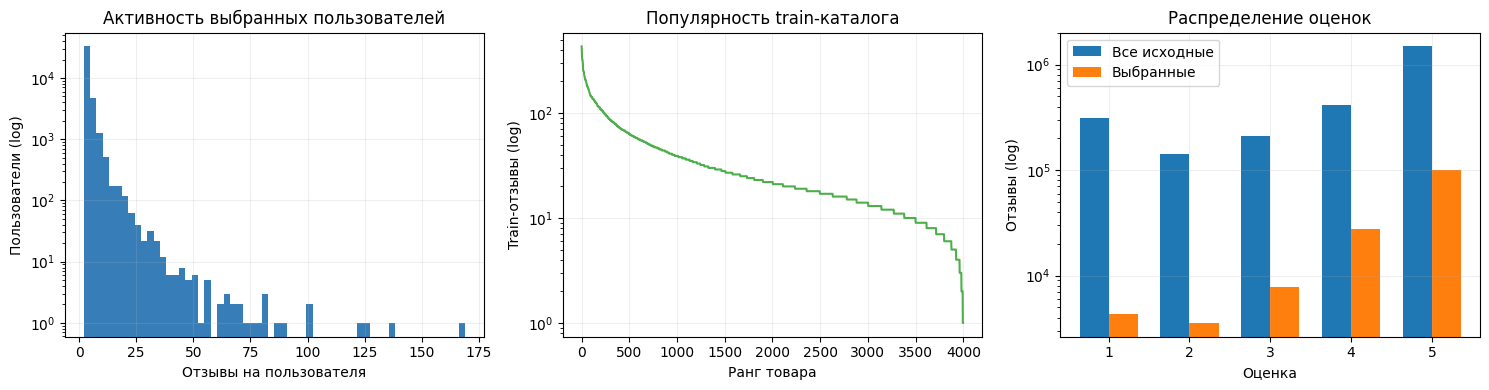

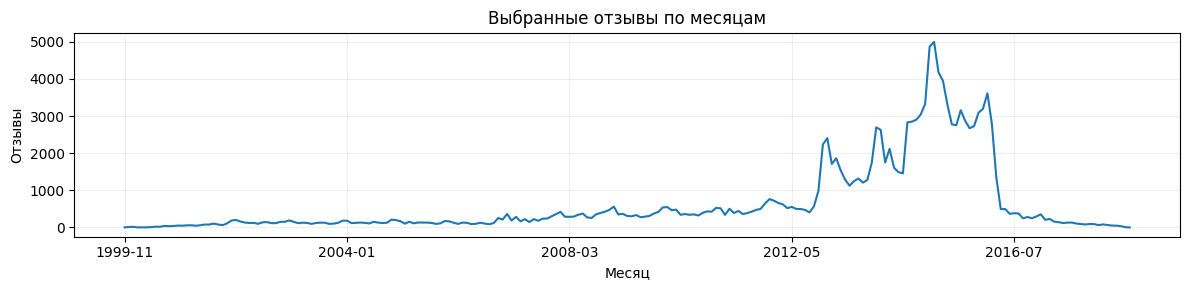

In [3]:
summary = pd.DataFrame([
    ['Исходные',len(raw),raw.user_id.nunique(),raw.item_id.nunique()],
    ['Выбранные',len(events),shape[0],shape[1]],
    ['Train',len(train),train.user_id.nunique(),train.item_id.nunique()],
    ['Validation',len(val),val.user_id.nunique(),val.item_id.nunique()],
    ['Test',len(test),test.user_id.nunique(),test.item_id.nunique()]],
    columns=['Этап','Отзывы','Пользователи','Товары'])
display(summary)
print('Пропуски исходных полей:',report['missing'])
print('Точных дубликатов:',report['exact_duplicates'])
print('Повторных user/item строк (включая точные):',report['repeated_user_item_rows'])
print(f"Разреженность выбранной матрицы: {report['sparsity']:.6%}")
display(meta[['item_id','title','brand','category']].head(8))
fig, axes = plt.subplots(1,3,figsize=(15,4))
axes[0].hist(events.groupby('user_id').size(),bins=60,log=True,color='#377eb8')
axes[0].set(xlabel='Отзывы на пользователя',ylabel='Пользователи (log)',title='Активность выбранных пользователей')
pop = train.groupby('item_id').size().sort_values(ascending=False).to_numpy()
axes[1].plot(np.arange(1,len(pop)+1),pop,color='#4daf4a')
axes[1].set(yscale='log',xlabel='Ранг товара',ylabel='Train-отзывы (log)',title='Популярность train-каталога')
axes[2].bar(raw.rating.value_counts().sort_index().index-.18,raw.rating.value_counts().sort_index(),width=.36,label='Все исходные')
axes[2].bar(events.rating.value_counts().sort_index().index+.18,events.rating.value_counts().sort_index(),width=.36,label='Выбранные')
axes[2].set(yscale='log',xlabel='Оценка',ylabel='Отзывы (log)',title='Распределение оценок')
axes[2].legend()
plt.tight_layout(); plt.show()
monthly = events.assign(month=pd.to_datetime(events.timestamp,unit='s').dt.to_period('M').astype(str)).groupby('month').size()
monthly.plot(figsize=(12,3),title='Выбранные отзывы по месяцам',xlabel='Месяц',ylabel='Отзывы')
plt.tight_layout(); plt.show()

### Какие признаки получает FM

Помимо user/item ID используются бренд, последняя категория из списка и
слово из названия товара. Бренд нужен, чтобы связать товары одного издателя,
категория — похожие типы товаров. Слова в названиях могут связывать игры
одной серии или похожие издания.

Словари строятся по товарам из train. Бренд оставляется отдельным значением,
если встречается хотя бы дважды. Для названий берутся до 2048 частых слов
из трёх и более латинских букв, встречающихся минимум в пяти названиях.
HTML и служебные слова удаляются. Из подходящих слов товара выбирается самое
редкое, при равной частоте — по алфавиту. Для пропусков и редких значений
есть `unknown`.

Один признак из названия — довольно грубое представление, зато число
признаков получается небольшим. Дополнительно будет FM только с ID,
чтобы проверить, что изменилось после добавления метаданных.

Считается, что название, бренд и категория были известны при появлении товара.
В данных есть только поздний снимок этих полей, поэтому проверить, менялись
ли они со временем, нельзя. Цены, тексты отзывов, sales rank и also-bought
не используются.

metadata_source_rows      84819.000000
metadata_item_coverage        0.998498
brand_coverage                0.993744
category_coverage             0.993994
dtype: float64

brand_values              224.000000
title_values              778.000000
category_values           790.000000
brand_encoded_coverage      0.916166
title_encoded_coverage      0.971972
dtype: float64

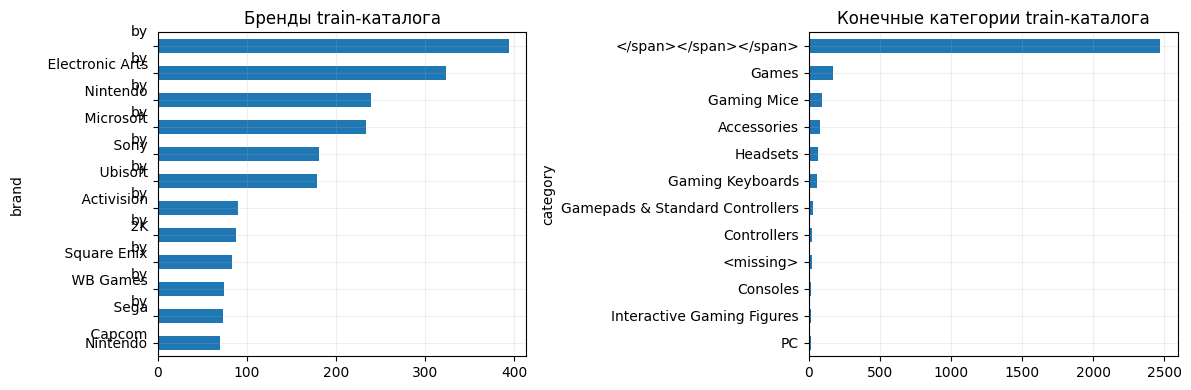

In [4]:
display(pd.Series({k:report[k] for k in ['metadata_source_rows','metadata_item_coverage','brand_coverage','category_coverage']}))
display(pd.Series(report['features']))
fig, axes = plt.subplots(1,2,figsize=(12,4))
meta.brand.fillna('<missing>').value_counts().head(12).sort_values().plot.barh(ax=axes[0],title='Бренды train-каталога')
meta.category.map(lambda x:x[-1] if isinstance(x,list) and x else '<missing>').value_counts().head(12).sort_values().plot.barh(ax=axes[1],title='Конечные категории train-каталога')
plt.tight_layout(); plt.show()

## 3. Как сравниваются модели

Сначала модели обучаются на train, а параметры выбираются по validation.
После этого лучшие варианты заново обучаются на train+validation и
оцениваются на test. Состав каталога и словари признаков остаются прежними.

Для каждого пользователя ранжируются **все товары каталога**, кроме уже
оценённых им в прошлом. Товары с прошлыми низкими оценками тоже исключаются.
Случайно выбранных отрицательных кандидатов при оценке нет.

Оцениваются пользователи, у которых в будущем периоде есть хотя бы один
подходящий отзыв на 4–5. Новые пользователи и товары вне train-подвыборки
в сравнение не входят. У всех моделей одинаковые пользователи, кандидаты
и правила исключения. При равном score порядок определяется по ASIN.

Основная метрика для подбора — **NDCG@10**: важно, насколько высоко находятся
нужные товары. Вторая — **Recall@10**: какую долю будущих положительных
товаров удалось найти.

$$\mathrm{Recall@10}(u)=\frac{|R_u^{10}\cap T_u|}{|T_u|},\qquad
\mathrm{NDCG@10}(u)=\frac{\sum_{j=1}^{10}\mathbf1[i_j\in T_u]/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|T_u|)}1/\log_2(j+1)}.$$

$T_u$ — будущие положительные товары, которых ещё нет в истории пользователя.
Метрики усредняются по пользователям. В таблицах также есть Precision@10 и
доля каталога, попавшая хотя бы в одну рекомендацию (Coverage@10).
Критерий положительного товара одинаков даже у моделей с разными обучающими таргетами.

In [5]:
val_context = evaluation_context(train,val,shape)
print('Граница train:',pd.to_datetime(data['t0'],unit='s'),'(не включительно)')
print('Граница validation:',pd.to_datetime(data['t1'],unit='s'),'(не включительно)')
display(pd.Series(val_context['report'],name='Validation protocol'))
train_positive = matrix(train,shape,positive_only=True)
print('Положительные train-взаимодействия:',train_positive.nnz)
from checks import run_checks
run_checks()

Граница train: 2016-03-09 00:00:00 (не включительно)
Граница validation: 2017-01-23 00:00:00 (не включительно)


relevant_rows             3154
eligible_relevant_rows    3154
excluded_cold_rows           0
excluded_seen_rows           0
evaluated_users           1888
candidate_catalog         3996
Name: Validation protocol, dtype: int64

Положительные train-взаимодействия: 123326
Passed: weighted ALS optimum, custom target, EASE stationarity, KNN constraints, FM gradient/scoring, ranking and exclusion.


## 4. Модели

Для каждой модели есть отдельный файл в `models/`. Обучение написано на NumPy
и SciPy. Выбор top-10 и подсчёт метрик общие для всех моделей.

### Item-based CF

В `item_knn.py` используется бинарная матрица положительных отзывов
$X_{ui}=\mathbf1[r_{ui}\ge4]$. Сходство товаров — косинус со штрафом за
малое число общих пользователей:

$$s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+\gamma}.$$

Диагональ обнуляется, для каждого исходного товара остаются $k$ соседей.
Рекомендации получаются из $XS$.

### iALS

В `ials.py` положительному отзыву соответствует $p_{ui}=1$, остальным парам — 0.
Для любого известного отзыва $c_{ui}=1+\alpha$, для неизвестных пар — 1.
Поэтому низкая оценка отличается от отсутствия отзыва: цель нулевая в обоих
случаях, но confidence разный.

$$\min_{A,B}\sum_{ui}c_{ui}(p_{ui}-a_u^Tb_i)^2+
\lambda(\|A\|_F^2+\|B\|_F^2).$$

По очереди фиксируются факторы товаров и пользователей. Обновление пользователя:

$$a_u=(B^TB+B_{I_u}^T(C_u-I)B_{I_u}+\lambda I)^{-1}B_{I_u}^TC_up_{u,I_u}.$$

Для товаров обновление аналогичное. В коде решается линейная система, без
явного вычисления обратной матрицы.

### EASE

В `ease.py` модель восстанавливает положительные взаимодействия через другие товары:

$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\qquad\mathrm{diag}(W)=0.$$

Если $P=(X^TX+\lambda I)^{-1}$, то $W_{ij}=-P_{ij}/P_{jj}$, а $W_{jj}=0$.
Score равен $XW$. Для решения используется разложение Холецкого.
Память растёт как $O(n^2)$, время факторизации — как $O(n^3)$ по числу товаров.

### FM с метаданными

В `fm.py` взаимодействуют пары признаков пользователя и товара:

$$f(z)=\sum_jw_jz_j+\frac12\sum_{d=1}^D
\left[(\sum_jv_{jd}z_j)^2-\sum_jv_{jd}^2z_j^2\right].$$

Обучение — BPR. Для положительной пары $(u,i)$ выбирается случайный товар $j$,
который пользователь ещё не оценивал в train. Минимизируется
$\log(1+\exp(-(f(u,i)-f(u,j))))$ с L2-регуляризацией участвующих признаков.
На каждый положительный отзыв берётся один отрицательный пример за эпоху.
Примеры пересэмплируются, известные отзывы с низкой оценкой не берутся в negatives.
Градиенты и обновления Adagrad реализованы вручную.

### iALS с собственным таргетом

В `custom_ials.py` меняется целевой сигнал:

$$p^*_{ui}=\frac{r_{ui}-3}{2}
\left[\beta+(1-\beta)e^{-(t_{cut}-t_{ui})/(86400\tau)}\right],\qquad\beta=0.5.$$

Для неизвестных пар $p^*=0$. Один балл даёт отрицательную цель, три — ноль,
пять — положительную. Старые отзывы ослабляются, но сохраняют хотя бы половину
исходного сигнала. $\tau$ измеряется в днях, $t_{cut}$ — начало будущего периода.

Идея — учитывать не только порог 4–5, но и силу оценки, а также её давность.
Confidence остаётся тем же, что у обычного iALS. Таким образом меняется именно
таргет. Релевантность при оценке на test по-прежнему определяется порогом 4–5.

### Подбор параметров

Ниже заданы небольшие сетки параметров. Для случайных операций используется
seed 42. Лучший вариант выбирается по validation NDCG@10; при равенстве
остаётся первый в сетке. Число эпох фиксировано, test для подбора не используется.

У custom iALS сетка больше из-за двух значений $\tau$. У FM без метаданных
настройки такие же, как у выбранного FM с метаданными: отдельно они не подбираются.
Поэтому это сравнение добавления признаков при одних настройках.

In [6]:
classes = {'ItemKNN':ItemKNN,'iALS':IALS,'EASE':EASE,'FM+metadata':FM,'Custom iALS':CustomIALS}
grids = {
    'ItemKNN':[{'k':50,'shrink':10},{'k':150,'shrink':10},{'k':100,'shrink':50}],
    'iALS':[{'factors':16,'reg':1.,'alpha':20.,'epochs':6,'seed':SEED},
            {'factors':32,'reg':5.,'alpha':20.,'epochs':6,'seed':SEED}],
    'EASE':[{'reg':50.},{'reg':200.},{'reg':1000.}],
    'FM+metadata':[{'factors':16,'lr':lr,'reg':.001,'epochs':12,
                    'batch_size':1024,'seed':SEED,'metadata':True} for lr in [.03,.08]],
    'Custom iALS':[{'factors':f,'reg':r,'alpha':20.,'epochs':6,'seed':SEED,
                     'tau_days':tau,'floor':.5}
                   for f,r in [(16,1.),(32,5.)] for tau in [180.,730.]]}
display(pd.DataFrame([{'model':name,'trials':len(g),'settings':json.dumps(g)} for name,g in grids.items()]))
(OUT/'grids.json').write_text(json.dumps(grids,indent=2))
def fit_model(name,config,past,cutoff):
    obj = classes[name](**config)
    return obj.fit(matrix(past,shape,positive_only=True),events=past,
                   cutoff=cutoff,item_features=data['item_features'])
validation_rows, selected = [], {}
for name,configs in grids.items():
    best = -np.inf
    for config in configs:
        start = time.perf_counter()
        obj = fit_model(name,config,train,data['t0'])
        fit_seconds = time.perf_counter()-start
        scores,_ = evaluate(obj,val_context)
        row = dict(model=name,config=json.dumps(config,sort_keys=True),
                   fit_seconds=fit_seconds,**scores)
        validation_rows.append(row)
        pd.DataFrame(validation_rows).to_csv(OUT/'validation.csv',index=False)
        print(name,config,'NDCG@10',round(scores['NDCG@10'],5),'fit seconds',round(fit_seconds,2),flush=True)
        if scores['NDCG@10'] > best:
            selected[name] = config.copy()
            best = scores['NDCG@10']
        del obj
        gc.collect()
(OUT/'selected.json').write_text(json.dumps(selected,indent=2))
validation_table = pd.DataFrame(validation_rows)
display(validation_table.sort_values(['model','NDCG@10'],ascending=[True,False]))
display(pd.DataFrame([dict(model=n,**c) for n,c in selected.items()]).fillna('—'))

,model,trials,settings
0,ItemKNN,3,"[{""k"": 50, ""shrink"": 10}, {""k"": 150, ""shrink"":..."
1,iALS,2,"[{""factors"": 16, ""reg"": 1.0, ""alpha"": 20.0, ""e..."
2,EASE,3,"[{""reg"": 50.0}, {""reg"": 200.0}, {""reg"": 1000.0}]"
3,FM+metadata,2,"[{""factors"": 16, ""lr"": 0.03, ""reg"": 0.001, ""ep..."
4,Custom iALS,4,"[{""factors"": 16, ""reg"": 1.0, ""alpha"": 20.0, ""e..."


ItemKNN {'k': 50, 'shrink': 10} NDCG@10 0.02818 fit seconds 0.2


ItemKNN {'k': 150, 'shrink': 10} NDCG@10 0.02854 fit seconds 0.15


ItemKNN {'k': 100, 'shrink': 50} NDCG@10 0.02933 fit seconds 0.14


/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: divide by zero encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: overflow encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: invalid value encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: divide by zero encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: overflow encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: invalid value encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:46: RuntimeWarning: divide by zero enc

...

/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: divide by zero encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: overflow encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: invalid value encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: divide by zero encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: overflow encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: invalid value encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:46: RuntimeWarning: divide by zero enc

/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: divide by zero encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: overflow encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: invalid value encountered in matmul
  return self.user_factors[users] @ self.item_factors.T


Custom iALS {'factors': 32, 'reg': 5.0, 'alpha': 20.0, 'epochs': 6, 'seed': 42, 'tau_days': 730.0, 'floor': 0.5} NDCG@10 0.02952 fit seconds 4.42


,model,config,fit_seconds,NDCG@10,Recall@10,Precision@10,Coverage@10
12,Custom iALS,"{""alpha"": 20.0, ""epochs"": 6, ""factors"": 32, ""f...",4.394712,0.031611,0.055811,0.008951,0.180931
13,Custom iALS,"{""alpha"": 20.0, ""epochs"": 6, ""factors"": 32, ""f...",4.421616,0.029521,0.052156,0.008369,0.173173
10,Custom iALS,"{""alpha"": 20.0, ""epochs"": 6, ""factors"": 16, ""f...",3.018115,0.026779,0.045343,0.007044,0.106857
11,Custom iALS,"{""alpha"": 20.0, ""epochs"": 6, ""factors"": 16, ""f...",3.000263,0.025892,0.043908,0.006674,0.104354
5,EASE,"{""reg"": 50.0}",2.755217,0.032015,0.054441,0.008951,0.616116
6,EASE,"{""reg"": 200.0}",2.755097,0.031337,0.052830,0.008581,0.564565
7,EASE,"{""reg"": 1000.0}",2.771150,0.030996,0.051594,0.008316,0.542793
9,FM+metadata,"{""batch_size"": 1024, ""epochs"": 12, ""factors"": ...",3.673756,0.014180,0.025877,0.004290,0.195195
8,FM+metadata,"{""batch_size"": 1024, ""epochs"": 12, ""factors"": ...",3.696543,0.012443,0.025262,0.004025,0.043544
2,ItemKNN,"{""k"": 100, ""shrink"": 50}",0.140364,0.029330,0.049997,0.008104,0.709960


,model,k,shrink,factors,reg,alpha,epochs,seed,lr,batch_size,metadata,tau_days,floor
0,ItemKNN,100.0,50.0,—,—,—,—,—,—,—,—,—,—
1,iALS,—,—,32.0,5.0,20.0,6.0,42.0,—,—,—,—,—
2,EASE,—,—,—,50.0,—,—,—,—,—,—,—,—
3,FM+metadata,—,—,16.0,0.001,—,12.0,42.0,0.08,1024.0,True,—,—
4,Custom iALS,—,—,32.0,5.0,20.0,6.0,42.0,—,—,—,180.0,0.5


## 5. Результаты на test

Теперь обучаются выбранные варианты на train+validation. В общей таблице
приведены метрики и параметры. FM ID-only добавлен для сравнения с FM,
в которой есть метаданные.

relevant_rows             1590
eligible_relevant_rows    1590
excluded_cold_rows           0
excluded_seen_rows           0
evaluated_users           1098
candidate_catalog         3996
Name: Test protocol, dtype: int64

ItemKNN NDCG@10 0.02774


/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: divide by zero encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: overflow encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:38: RuntimeWarning: invalid value encountered in matmul
  base = fixed.T @ fixed + self.reg * np.eye(self.factors)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: divide by zero encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: overflow encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:45: RuntimeWarning: invalid value encountered in matmul
  lhs = base + self.alpha * (y.T @ y)
/Users/alenab0br/recsys-homework1/models/ials.py:46: RuntimeWarning: divide by zero enc

iALS NDCG@10 0.02466


/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: divide by zero encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: overflow encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: invalid value encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: divide by zero encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: overflow encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: invalid value encountered in matmul
  return self.user_factors[users] @ self.item_factors.T


...

Custom iALS NDCG@10 0.02172


/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: divide by zero encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: overflow encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: invalid value encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: divide by zero encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: overflow encountered in matmul
  return self.user_factors[users] @ self.item_factors.T
/Users/alenab0br/recsys-homework1/models/ials.py:51: RuntimeWarning: invalid value encountered in matmul
  return self.user_factors[users] @ self.item_factors.T


FM ID-only NDCG@10 0.01492


/Users/alenab0br/recsys-homework1/models/fm.py:94: RuntimeWarning: divide by zero encountered in matmul
  return self.v[users] @ self.item_sum.T + self.item_bias[None, :] + self.w[users, None]
/Users/alenab0br/recsys-homework1/models/fm.py:94: RuntimeWarning: overflow encountered in matmul
  return self.v[users] @ self.item_sum.T + self.item_bias[None, :] + self.w[users, None]
/Users/alenab0br/recsys-homework1/models/fm.py:94: RuntimeWarning: invalid value encountered in matmul
  return self.v[users] @ self.item_sum.T + self.item_bias[None, :] + self.w[users, None]
/Users/alenab0br/recsys-homework1/models/fm.py:94: RuntimeWarning: divide by zero encountered in matmul
  return self.v[users] @ self.item_sum.T + self.item_bias[None, :] + self.w[users, None]
/Users/alenab0br/recsys-homework1/models/fm.py:94: RuntimeWarning: overflow encountered in matmul
  return self.v[users] @ self.item_sum.T + self.item_bias[None, :] + self.w[users, None]
/Users/alenab0br/recsys-homework1/models/fm.py:9

,parameters,fit_seconds,NDCG@10,Recall@10,Precision@10,Coverage@10
model,,,,,,
EASE,"{""reg"": 50.0}",2.790239,0.029882,0.051473,0.007559,0.505255
ItemKNN,"{""k"": 100, ""shrink"": 50}",0.171419,0.027743,0.046967,0.006648,0.573323
iALS,"{""alpha"": 20.0, ""epochs"": 6, ""factors"": 32, ""reg"": 5.0, ""seed"": 42}",4.405197,0.024658,0.045754,0.007013,0.177177
Custom iALS,"{""alpha"": 20.0, ""epochs"": 6, ""factors"": 32, ""floor"": 0.5, ""reg"": 5.0, ""seed"": 42, ""tau_days"": 180.0}",4.403979,0.021721,0.040080,0.005738,0.165415
FM+metadata,"{""batch_size"": 1024, ""epochs"": 12, ""factors"": 16, ""lr"": 0.08, ""metadata"": true, ""reg"": 0.001, ""seed"": 42}",3.837447,0.017522,0.029953,0.003734,0.164414
FM ID-only,"{""batch_size"": 1024, ""epochs"": 12, ""factors"": 16, ""lr"": 0.08, ""metadata"": false, ""reg"": 0.001, ""seed"": 42}",2.260907,0.014916,0.031388,0.004189,0.185686


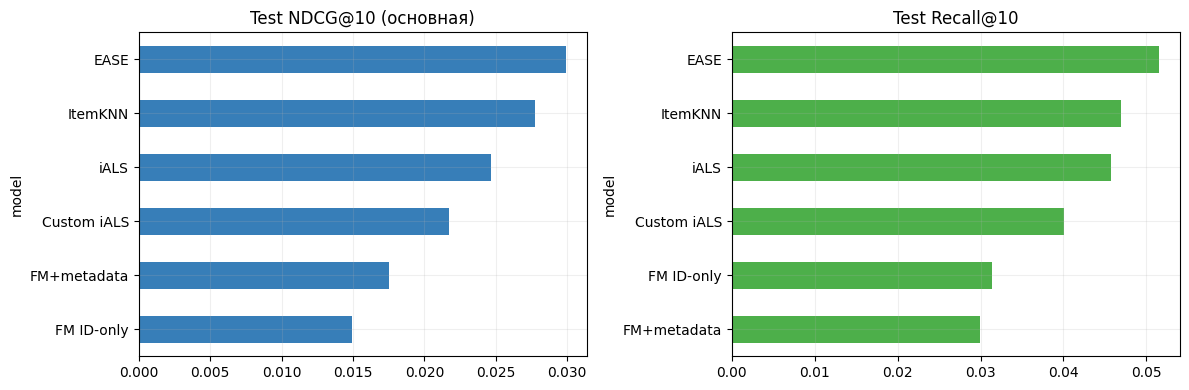

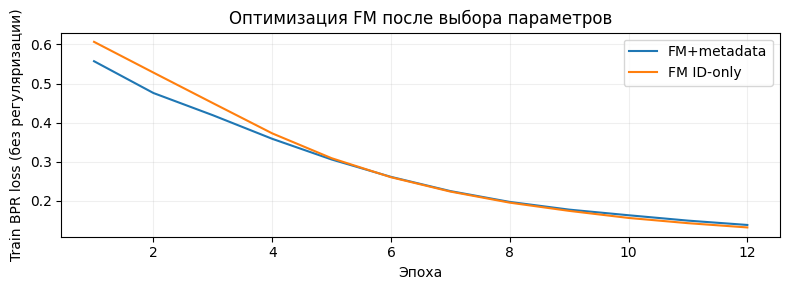

In [7]:
past = pd.concat([train,val],ignore_index=True)
test_context = evaluation_context(past,test,shape)
display(pd.Series(test_context['report'],name='Test protocol'))
final_rows, user_metrics, fm_losses, examples = [], {}, {}, {}
example_users = test_context['users'][:3]
def final_run(label,name,config):
    start=time.perf_counter()
    obj=fit_model(name,config,past,data['t1'])
    seconds=time.perf_counter()-start
    scores,per_user=evaluate(obj,test_context)
    user_metrics[label]=per_user
    per_user.to_csv(OUT/(label.replace(' ','_').replace('+','_')+'_per_user.csv'),index=False)
    examples[label]=recommend(obj,example_users,test_context).tolist()
    if isinstance(obj,FM): fm_losses[label]=obj.losses
    final_rows.append(dict(model=label,parameters=json.dumps(config,sort_keys=True),
                           fit_seconds=seconds,**scores))
    pd.DataFrame(final_rows).to_csv(OUT/'test.csv',index=False)
    print(label,'NDCG@10',round(scores['NDCG@10'],5),flush=True)
    del obj
    gc.collect()
for name,config in selected.items():
    final_run(name,name,config)
ablation_config={**selected['FM+metadata'],'metadata':False}
final_run('FM ID-only','FM+metadata',ablation_config)
results=pd.DataFrame(final_rows).set_index('model').sort_values('NDCG@10',ascending=False)
with pd.option_context('display.max_colwidth', None):
    display(results)
fig,axes=plt.subplots(1,2,figsize=(12,4))
results['NDCG@10'].sort_values().plot.barh(ax=axes[0],color='#377eb8',title='Test NDCG@10 (основная)')
results['Recall@10'].sort_values().plot.barh(ax=axes[1],color='#4daf4a',title='Test Recall@10')
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,3))
for name,loss in fm_losses.items():ax.plot(range(1,len(loss)+1),loss,label=name)
ax.set(xlabel='Эпоха',ylabel='Train BPR loss (без регуляризации)',title='Оптимизация FM после выбора параметров')
ax.legend();plt.tight_layout();plt.show()

### Насколько устойчивы различия

Дополнительно сравним custom iALS с базовым iALS и две версии FM.
Для разности NDCG@10 построим 95% bootstrap-интервал: 2000 раз выберем
пользователей с возвращением, каждый раз одних и тех же для обеих моделей.
Если интервал включает ноль, уверенно говорить об улучшении по этому
эксперименту нельзя. Такая проверка не учитывает другие seeds и разбиения;
поправка на множественные сравнения не делается.

Ниже также приведены top-10 для одного пользователя.

In [8]:
rng=np.random.default_rng(SEED)
contrasts=[]
for a,b in [('Custom iALS','iALS'),('FM+metadata','FM ID-only')]:
    aa=user_metrics[a].set_index('user_idx')['NDCG@10']
    bb=user_metrics[b].set_index('user_idx')['NDCG@10']
    assert aa.index.equals(bb.index)
    delta=(aa-bb).to_numpy()
    boot=np.array([rng.choice(delta,size=len(delta),replace=True).mean() for _ in range(2000)])
    lo,hi=np.quantile(boot,[.025,.975])
    contrasts.append(dict(comparison=a+' − '+b,delta=float(delta.mean()),lower=float(lo),upper=float(hi)))
contrasts=pd.DataFrame(contrasts)
display(contrasts)
contrasts.to_csv(OUT/'paired_differences.csv',index=False)
rows=[]
for name,recs in examples.items():
    u=int(example_users[0])
    for rank,i in enumerate(recs[0],1):
        rows.append(dict(model=name,rank=rank,item_id=meta.iloc[i].item_id,
                         title=meta.iloc[i].get('title',''),
                         relevant=i in test_context['truth'][u]))
display(pd.DataFrame(rows))

,comparison,delta,lower,upper
0,Custom iALS − iALS,-0.002936,-0.007105,0.001069
1,FM+metadata − FM ID-only,0.002606,-0.004264,0.009867


,model,rank,item_id,title,relevant
0,ItemKNN,1,B0050SYX8W,Halo 4 - Xbox 360 (Standard Game),False
1,ItemKNN,2,B001HWB68K,Halo 3,False
2,ItemKNN,3,B002BSA20M,Halo Reach,False
3,ItemKNN,4,B0012N3T3Y,Resistance 2 - Playstation 3,False
4,ItemKNN,5,B0017HW5LM,Halo Wars - Xbox 360,False
5,ItemKNN,6,B000FRU0NU,Halo 3 - Xbox 360,False
6,ItemKNN,7,B0050SX97I,Metal Gear Solid HD Collection,False
7,ItemKNN,8,B00008J7NZ,Halo 2 - Xbox,False
8,ItemKNN,9,B002I0H79C,Gears of War 3,False
9,ItemKNN,10,B00503E8S2,Call of Duty: Modern Warfare 3 - Xbox 360,False


## 6. Выводы

Лучшей в итоговой таблице оказалась **EASE с λ = 50**: NDCG@10 = 0,0299,
Recall@10 = 0,0515. Увеличение λ до 200 и 1000 ухудшало результат на validation.
На втором месте на test — item-based CF с 100 соседями и shrinkage 50.
Для этой подвыборки простые модели связей между товарами оказались сильными.

У базового iALS вариант с 32 факторами и λ = 5 был лучше на validation,
чем вариант с 16 факторами и λ = 1. Эти параметры менялись вместе, поэтому
по этому сравнению нельзя отдельно оценить пользу увеличения числа факторов.

**Собственный таргет не дал улучшения на test.** На validation его лучший
результат был 0,0316 против 0,0300 у базового iALS. Но на test получилось
0,0217 против 0,0247. То есть небольшой выигрыш на validation не перенёсся
на следующий период. Возможно, сигнал хуже обобщается во времени;
по одному разбиению причину установить нельзя. При этом одновременно
менялись и шкала оценок, и учёт давности — их вклад отдельно не проверялся.

**У FM метаданные помогли NDCG, но не Recall.** NDCG вырос с 0,0149 до 0,0175,
а Recall снизился с 0,0314 до 0,0300. Эти метрики оценивают разные стороны
списка: NDCG учитывает позиции, Recall — долю найденных товаров.
Однозначного выигрыша по обеим метрикам нет. Кроме того, обе версии FM
в этой настройке уступили остальным моделям.

Оба bootstrap-интервала ниже включают ноль. Поэтому наблюдаемые изменения
от метаданных и нового таргета нельзя считать устойчивым улучшением.

In [9]:
winner=results.index[0]
lines=[f"Лучший результат в этом эксперименте: **{winner}**, "
       f"NDCG@10 = **{results.iloc[0]['NDCG@10']:.4f}**, Recall@10 = **{results.iloc[0]['Recall@10']:.4f}**.",
       f"Итоговая выборка: {len(events):,} отзывов, {shape[0]:,} пользователей, {shape[1]:,} товаров. "
       f"В финальной оценке {len(test_context['users']):,} пользователей."]
for row in contrasts.itertuples():
    interpretation = ('интервал включает ноль; надёжный выигрыш этим экспериментом не установлен'
                      if row.lower <= 0 <= row.upper else
                      'интервал лежит выше нуля' if row.lower > 0 else 'интервал лежит ниже нуля')
    lines.append(f"**{row.comparison}:** ΔNDCG@10 = {row.delta:+.4f}, "
                 f"95% CI [{row.lower:+.4f}, {row.upper:+.4f}]; {interpretation}.")
lines.append('Выбранные настройки приведены в общей test-таблице и `results/selected.json`; '
             'каждый выбор сделан по validation NDCG@10. Результат custom iALS проверяет '
             'совместный эффект знакового рейтингового и временного сигнала: отдельные '
             'эффекты этих компонентов в этой работе не идентифицированы.')
display(Markdown('\n\n'.join(lines)))
audit=dict(versions=versions,data=report,validation_protocol=val_context['report'],
           test_protocol=test_context['report'],selected=selected)
(OUT/'audit.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2))
(OUT/'conclusions.txt').write_text('\n\n'.join(lines))

Лучший результат в этом эксперименте: **EASE**, NDCG@10 = **0.0299**, Recall@10 = **0.0515**.

Итоговая выборка: 143,803 отзывов, 40,000 пользователей, 3,996 товаров. В финальной оценке 1,098 пользователей.

**Custom iALS − iALS:** ΔNDCG@10 = -0.0029, 95% CI [-0.0071, +0.0011]; интервал включает ноль; надёжный выигрыш этим экспериментом не установлен.

**FM+metadata − FM ID-only:** ΔNDCG@10 = +0.0026, 95% CI [-0.0043, +0.0099]; интервал включает ноль; надёжный выигрыш этим экспериментом не установлен.

Выбранные настройки приведены в общей test-таблице и `results/selected.json`; каждый выбор сделан по validation NDCG@10. Результат custom iALS проверяет совместный эффект знакового рейтингового и временного сигнала: отдельные эффекты этих компонентов в этой работе не идентифицированы.

793

### Что ограничивает результаты

Выборка содержит активных пользователей и популярные товары. Новые
пользователи, новые товары и остальная часть каталога здесь не проверялись.
Поэтому результат нельзя переносить на весь Amazon.

Отзыв — неполная информация о предпочтениях. Если пользователь не оставил
отзыв, это не означает, что товар ему не подходит. Кроме того, после удаления
повторных пар оцениваются рекомендации новых для пользователя товаров.

В метаданных нет истории изменений названий, брендов и категорий.
Их неизменность принята как допущение. У FM также довольно простое
представление названия и небольшая сетка параметров.

Эксперимент выполнен с одним seed и одним временным разбиением. Для более
надёжных выводов стоило бы повторить сравнение на нескольких периодах,
а у собственного таргета отдельно проверить влияние рейтинга и давности.

### Источники по моделям

- Hu, Koren, Volinsky (2008), [iALS](https://yifanhu.net/PUB/cf.pdf).
- Steck (2019), [EASE](https://arxiv.org/abs/1905.03375).
- Rendle (2010), [FM](https://doi.org/10.1109/ICDM.2010.127).
- Rendle et al. (2009), [BPR](https://arxiv.org/abs/1205.2618).